# 📊 Análise Exploratória dos Microdados do Censo Escolar 2025 (Versão 2)
**Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (INEP / MEC)**  
*Diretoria de Estatísticas Educacionais (DEED)*

---

### 🎯 Sobre este Notebook
Este notebook realiza uma **análise exploratória aprofundada, modular e de alto desempenho** sobre a **Versão 2 dos Microdados do Censo Escolar da Educação Básica 2025** (divulgado em julho de 2026).

#### 🔍 Contexto Metodológico Importante (LGPD e Granularidade):
Em conformidade com a **Lei nº 12.527/2011 (LAI)** e a **Lei nº 13.709/2018 (LGPD)**, os microdados do Censo Escolar são estruturados no nível de **estabelecimento de ensino**.
- A chave primária de integração de todas as tabelas é a variável `CO_ENTIDADE` (Código da Escola / Inep).
- As tabelas contêm dados cadastrais, quantitativos agregados de matrículas, turmas, docentes e gestores por unidade escolar.

---

### 🗺️ Sumário Executivo:
1. [Configuração do Ambiente e Utilitários Visuais](#1)
2. [Inspeção do Dicionário de Dados e Metadados](#2)
3. [Panorama do Universo Escolar Brasileiro (Tabela Escola)](#3)
4. [Raio-X da Infraestrutura Básica e Inclusão Digital](#4)
5. [Radiografia das Matrículas na Educação Básica (Tabela Matrícula)](#5)
6. [Educação Especial e Inclusão Escolar: Análise Geral e por Nível de Ensino](#6)
7. [A Política de Expansão do Tempo Integral](#7)
8. [Corpo Docente e Dinâmica de Turmas (Tabelas Docente e Turma)](#8)
9. [Liderança e Gestão Escolar (Tabela Gestor)](#9)
10. [Educação Profissional e Cursos Técnicos (Tabela Curso Técnico)](#10)
11. [Análise Integrada (Join Escola + Matrículas)](#11)
12. [Síntese dos Achados e Recomendações](#12)


<a id='1'></a>
## 1. Configuração do Ambiente e Utilitários Visuais

Configuração de bibliotecas, otimização de renderização com estilo profissional e funções de formatação em padrão brasileiro.


In [2]:
import os
import glob
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Configurações de exibição do Pandas e avisos
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))
warnings.filterwarnings('ignore')

# Configuração de estilo visual moderno e consistente
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16

# Paleta de cores corporativa personalizada
PALETA = {
    'primaria': '#1A365D',      # Azul meia-noite
    'secundaria': '#2B6CB0',    # Azul aço
    'destaque': '#DD6B20',      # Âmbar / Laranja queimado
    'sucesso': '#2F855A',       # Verde floresta
    'alerta': '#C53030',        # Vermelho carmesim
    'neutro_esc': '#2D3748',    # Cinza ardósia
    'neutro_cla': '#E2E8F0',    # Cinza suave
    'accent': '#805AD5',        # Púrpura elegante
    'inclusao': '#319795'       # Verde petróleo / inclusão
}
sns.set_palette([PALETA['primaria'], PALETA['secundaria'], PALETA['destaque'], PALETA['sucesso'], PALETA['accent']])

# Funções auxiliares para formatação de números em português
def fmt_num(val, pos=None):
    """Formata números com separador de milhar pt-BR (ponto)."""
    if pd.isna(val):
        return '-'
    return f'{int(val):,}'.replace(',', '.')

def fmt_pct(val, pos=None):
    """Formata porcentagem com 1 casa decimal e vírgula."""
    if pd.isna(val):
        return '-'
    return f'{val:.1f}%'.replace('.', ',')

print("✅ Ambiente configurado com sucesso!")


✅ Ambiente configurado com sucesso!


<a id='2'></a>
## 2. Inspeção do Dicionário de Dados e Metadados

O repositório fornece o dicionário oficial em formato Excel (`Anexos/ANEXO I - Dicionário de Dados/dicionário_dados_educação_básica.xlsx`).  
Criamos a função utilitária `consultar_dicionario` para pesquisar colunas, tipos e descrições sem precisar abrir a planilha externamente.


In [3]:
caminho_dict = os.path.join('Anexos', 'ANEXO I - Dicionário de Dados', 'dicionário_dados_educação_básica.xlsx')

def carregar_dicionario(tabela='Tabela_de_Escola'):
    """Carrega uma aba do dicionário de dados do Censo Escolar 2025."""
    try:
        df_d = pd.read_excel(caminho_dict, sheet_name=tabela, header=6)
        df_d = df_d.dropna(subset=['Nome da Variável']).copy()
        df_d = df_d[['Nome da Variável', 'Descrição da Variável', 'Tipo', 'Categoria']].dropna(subset=['Nome da Variável'])
        return df_d
    except Exception as e:
        print(f"Erro ao carregar dicionário: {e}")
        return pd.DataFrame()

def consultar_dicionario(termo, tabela='Tabela_de_Escola'):
    """Pesquisa variáveis no dicionário oficial pelo nome ou pela descrição."""
    df_d = carregar_dicionario(tabela)
    if df_d.empty:
        return df_d
    filtro = (
        df_d['Nome da Variável'].str.contains(termo, case=False, na=False) |
        df_d['Descrição da Variável'].str.contains(termo, case=False, na=False)
    )
    return df_d[filtro].head(15)

# Exemplo: consultar variáveis sobre água e internet na Tabela de Escola
print("🔎 Exemplo de consulta no Dicionário (Tabela de Escola - Termos 'AGUA' ou 'INTERNET'):")
display(consultar_dicionario('AGUA', 'Tabela_de_Escola'))
display(consultar_dicionario('INTERNET', 'Tabela_de_Escola'))


🔎 Exemplo de consulta no Dicionário (Tabela de Escola - Termos 'AGUA' ou 'INTERNET'):
Erro ao carregar dicionário: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.


""


Erro ao carregar dicionário: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.


""


<a id='3'></a>
## 3. Panorama do Universo Escolar Brasileiro (Tabela Escola)

A `Tabela_Escola_2025_V2.csv` possui **214.192 registros** e **290 variáveis**.  
Nela estão catalogadas todas as escolas brasileiras, incluindo sua situação de funcionamento (`TP_SITUACAO_FUNCIONAMENTO`), dependência administrativa (`TP_DEPENDENCIA`), localização geográfica e dados cadastrais.

> **Regra de Negócio Fundamental**: Para análises de atendimento escolar ativo, devemos filtrar escolas com `TP_SITUACAO_FUNCIONAMENTO == 1` (**Em Atividade**), excluindo escolas paralisadas (2) ou extintas (3).


In [4]:
# Carregamento otimizado selecionando colunas-chave
cols_escola = [
    'NU_ANO_CENSO', 'CO_ENTIDADE', 'NO_ENTIDADE', 'NO_REGIAO', 'CO_REGIAO',
    'NO_UF', 'SG_UF', 'CO_UF', 'NO_MUNICIPIO', 'CO_MUNICIPIO',
    'TP_DEPENDENCIA', 'TP_CATEGORIA_ESCOLA_PRIVADA', 'TP_LOCALIZACAO',
    'TP_LOCALIZACAO_DIFERENCIADA', 'TP_SITUACAO_FUNCIONAMENTO',
    # Infraestrutura essencial
    'IN_AGUA_POTAVEL', 'IN_AGUA_REDE_PUBLICA', 'IN_AGUA_INEXISTENTE',
    'IN_ENERGIA_REDE_PUBLICA', 'IN_ENERGIA_RENOVAVEL', 'IN_ENERGIA_INEXISTENTE',
    'IN_ESGOTO_REDE_PUBLICA', 'IN_ESGOTO_FOSSA_SEPTICA', 'IN_ESGOTO_INEXISTENTE',
    'IN_LIXO_SERVICO_COLETA', 'IN_LIXO_QUEIMA',
    # Ambientes pedagógicos e apoio
    'IN_BIBLIOTECA_SALA_LEITURA', 'IN_LABORATORIO_CIENCIAS', 'IN_LABORATORIO_INFORMATICA',
    'IN_QUADRA_ESPORTES', 'IN_REFEITORIO', 'IN_ALIMENTACAO',
    # Conectividade e tecnologia
    'IN_INTERNET', 'IN_INTERNET_ALUNOS', 'IN_INTERNET_APRENDIZAGEM',
    'IN_COMPUTADOR', 'IN_COMP_PORTATIL_ALUNO', 'QT_COMP_PORTATIL_ALUNO',
    # Acessibilidade e Educação Especial
    'IN_SALA_ATENDIMENTO_ESPECIAL', 'QT_SALAS_UTILIZADAS_ACESSIVEIS',
    'QT_PROF_TRAD_LIBRAS', 'QT_PROF_REVISOR_BRAILLE',
    'IN_ACESSIBILIDADE_RAMPAS', 'IN_ACESSIBILIDADE_CORRIMAO',
    'IN_ACESSIBILIDADE_ELEVADOR', 'IN_ACESSIBILIDADE_PISOS_TATEIS',
    'IN_ACESSIBILIDADE_INEXISTENTE'
]

caminho_escola = os.path.join('dados', 'Tabela_Escola_2025_V2.csv')
df_escola_total = pd.read_csv(caminho_escola, sep=';', encoding='latin1', usecols=cols_escola)
print(f"📦 Total de registros na base de escolas: {len(df_escola_total):,}".replace(',', '.'))

# Dicionários de mapeamento conforme documentação do INEP
MAP_SITUACAO = {1: 'Em atividade', 2: 'Paralisada', 3: 'Extinta'}
MAP_DEPENDENCIA = {1: 'Federal', 2: 'Estadual', 3: 'Municipal', 4: 'Privada'}
MAP_LOCALIZACAO = {1: 'Urbana', 2: 'Rural'}
MAP_LOC_DIFERENCIADA = {
    0: 'Não diferenciada',
    1: 'Área de assentamento',
    2: 'Terra indígena',
    3: 'Comunidade remanescente quilombola'
}

df_escola_total['DS_SITUACAO'] = df_escola_total['TP_SITUACAO_FUNCIONAMENTO'].map(MAP_SITUACAO)
df_escola_total['DS_DEPENDENCIA'] = df_escola_total['TP_DEPENDENCIA'].map(MAP_DEPENDENCIA)
df_escola_total['DS_LOCALIZACAO'] = df_escola_total['TP_LOCALIZACAO'].map(MAP_LOCALIZACAO)
df_escola_total['DS_LOCALIZACAO_DIF'] = df_escola_total['TP_LOCALIZACAO_DIFERENCIADA'].map(MAP_LOC_DIFERENCIADA)

# Filtro analítico: Escolas Em Atividade
df_escola = df_escola_total[df_escola_total['TP_SITUACAO_FUNCIONAMENTO'] == 1].copy()
print(f"🏫 Escolas ativas no Brasil em 2025: {len(df_escola):,}".replace(',', '.'))


📦 Total de registros na base de escolas: 214.192
🏫 Escolas ativas no Brasil em 2025: 180.540


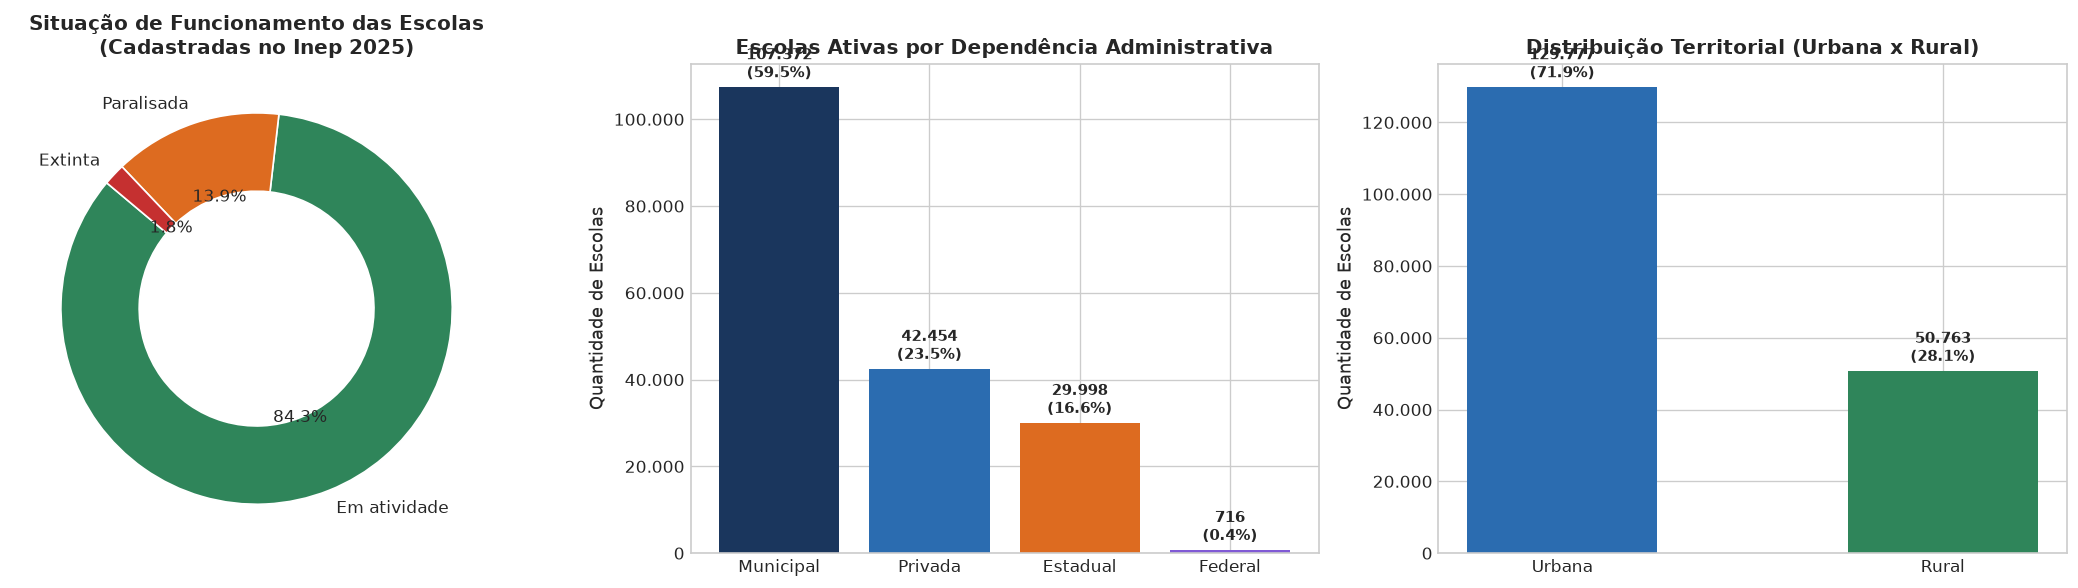

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Situação de Funcionamento
df_sit = df_escola_total['DS_SITUACAO'].value_counts()
cores_sit = [PALETA['sucesso'], PALETA['destaque'], PALETA['alerta']]
wedges, texts, autotexts = axes[0].pie(
    df_sit, labels=df_sit.index, autopct='%1.1f%%', startangle=140,
    colors=cores_sit, wedgeprops=dict(width=0.4, edgecolor='w')
)
axes[0].set_title('Situação de Funcionamento das Escolas\n(Cadastradas no Inep 2025)', fontsize=12)

# 2. Dependência Administrativa (Escolas Ativas)
df_dep = df_escola['DS_DEPENDENCIA'].value_counts()
bars_dep = axes[1].bar(df_dep.index, df_dep.values, color=[PALETA['primaria'], PALETA['secundaria'], PALETA['destaque'], PALETA['accent']])
axes[1].set_title('Escolas Ativas por Dependência Administrativa', fontsize=12)
axes[1].set_ylabel('Quantidade de Escolas')
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
for bar in bars_dep:
    h = bar.get_height()
    pct = (h / len(df_escola)) * 100
    axes[1].annotate(f'{fmt_num(h)}\n({pct:.1f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

# 3. Localização (Urbana vs Rural)
df_loc = df_escola['DS_LOCALIZACAO'].value_counts()
bars_loc = axes[2].bar(df_loc.index, df_loc.values, color=[PALETA['secundaria'], PALETA['sucesso']], width=0.5)
axes[2].set_title('Distribuição Territorial (Urbana x Rural)', fontsize=12)
axes[2].set_ylabel('Quantidade de Escolas')
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
for bar in bars_loc:
    h = bar.get_height()
    pct = (h / len(df_escola)) * 100
    axes[2].annotate(f'{fmt_num(h)}\n({pct:.1f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


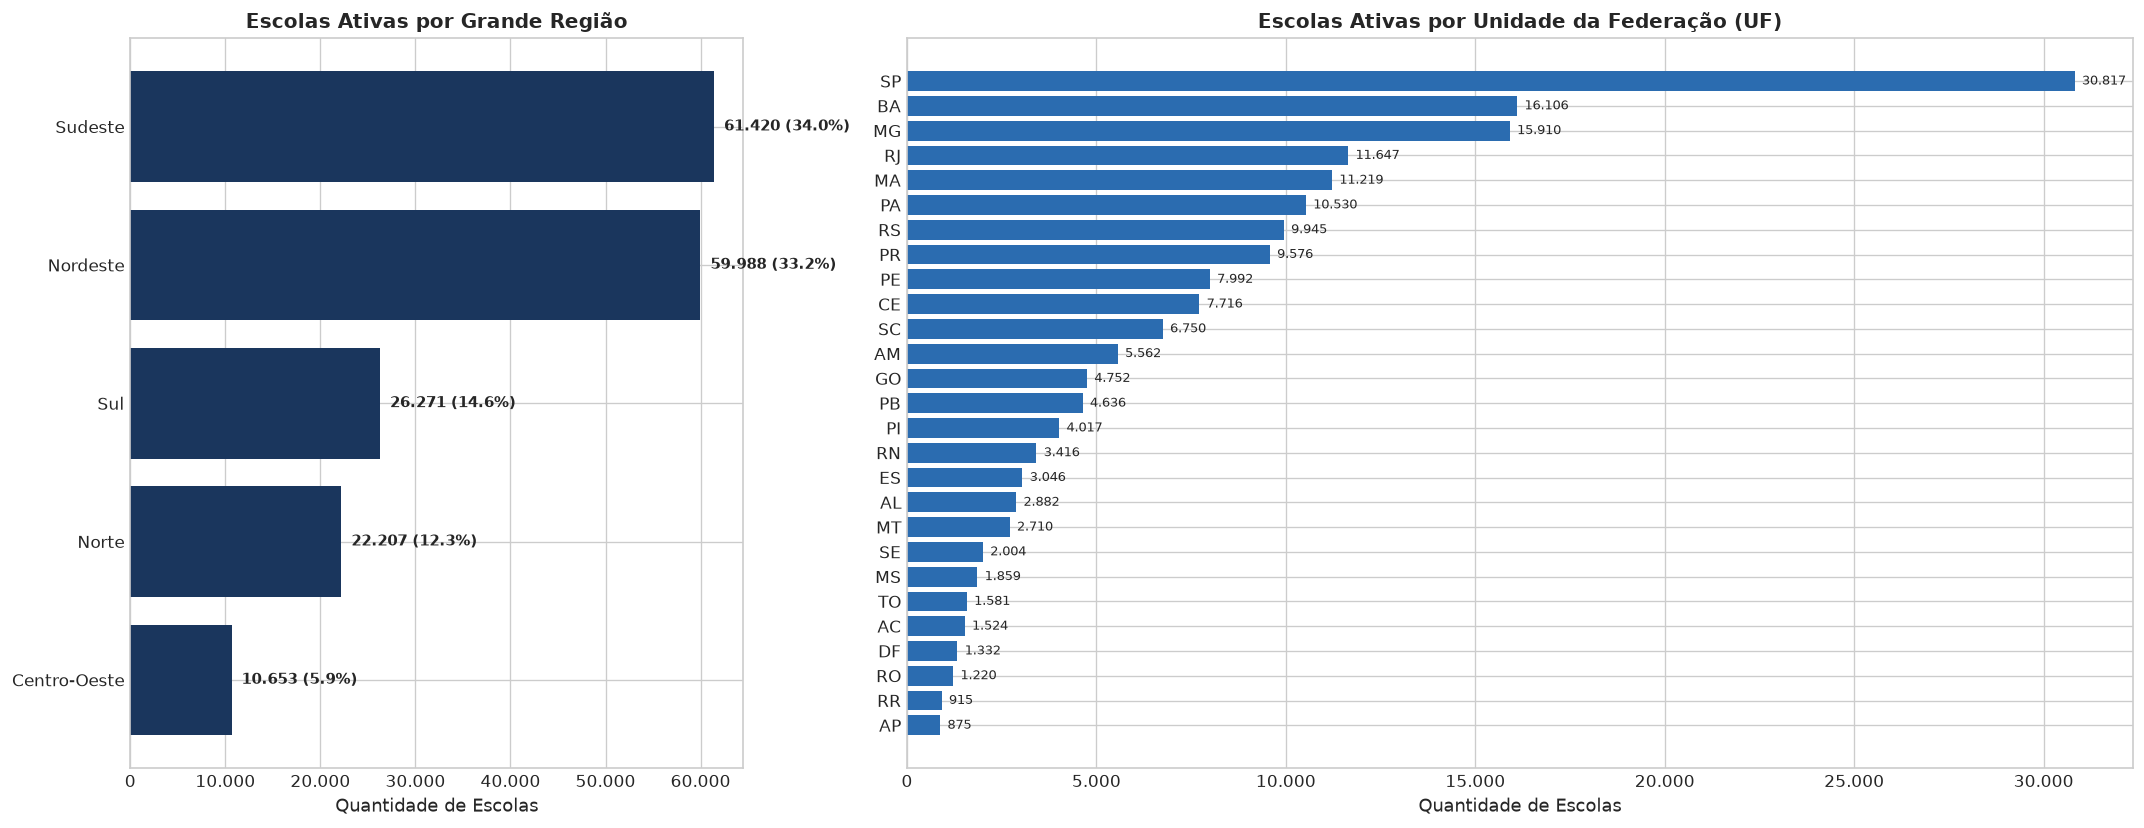

In [6]:
# Distribuição de Escolas Ativas por Região e Unidade da Federação
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 2]})

# Por Região
df_reg = df_escola['NO_REGIAO'].value_counts().sort_values(ascending=True)
bars_reg = axes[0].barh(df_reg.index, df_reg.values, color=PALETA['primaria'])
axes[0].set_title('Escolas Ativas por Grande Região', fontsize=12)
axes[0].set_xlabel('Quantidade de Escolas')
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
for bar in bars_reg:
    w = bar.get_width()
    pct = (w / len(df_escola)) * 100
    axes[0].annotate(f' {fmt_num(w)} ({pct:.1f}%)',
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

# Por Unidade Federativa (UF)
df_uf = df_escola['SG_UF'].value_counts().sort_values(ascending=True)
bars_uf = axes[1].barh(df_uf.index, df_uf.values, color=PALETA['secundaria'])
axes[1].set_title('Escolas Ativas por Unidade da Federação (UF)', fontsize=12)
axes[1].set_xlabel('Quantidade de Escolas')
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
for bar in bars_uf:
    w = bar.get_width()
    axes[1].annotate(f' {fmt_num(w)}',
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(2, 0), textcoords="offset points",
                     va='center', fontsize=8)

plt.tight_layout()
plt.show()


<a id='4'></a>
## 4. Raio-X da Infraestrutura Escolar e Inclusão Digital

A infraestrutura das escolas é um dos determinantes mais fortes da qualidade e equidade educacional.  
Analisamos serviços básicos, espaços pedagógicos e conectividade digital no país.


In [8]:
itens_infra = {
    'Água Potável': 'IN_AGUA_POTAVEL',
    'Energia (Rede Pública)': 'IN_ENERGIA_REDE_PUBLICA',
    'Esgoto (Rede Pública)': 'IN_ESGOTO_REDE_PUBLICA',
    'Esgoto (Fossa Séptica)': 'IN_ESGOTO_FOSSA_SEPTICA',
    'Coleta de Lixo': 'IN_LIXO_SERVICO_COLETA',
    'Internet (Geral)': 'IN_INTERNET',
    'Internet para Alunos': 'IN_INTERNET_ALUNOS',
    'Lab. Informática': 'IN_LABORATORIO_INFORMATICA',
    'Lab. Ciências': 'IN_LABORATORIO_CIENCIAS',
    'Biblioteca / Sala Leitura': 'IN_BIBLIOTECA_SALA_LEITURA',
    'Quadra de Esportes': 'IN_QUADRA_ESPORTES',
    'Refeitório': 'IN_REFEITORIO'
}

dados_infra = []
for nome, col in itens_infra.items():
    pct_total = (df_escola[col].fillna(0) == 1).mean() * 100
    pct_urb = (df_escola[df_escola['TP_LOCALIZACAO'] == 1][col].fillna(0) == 1).mean() * 100
    pct_rur = (df_escola[df_escola['TP_LOCALIZACAO'] == 2][col].fillna(0) == 1).mean() * 100
    dados_infra.append({'Indicador': nome, 'Brasil': pct_total, 'Urbana': pct_urb, 'Rural': pct_rur})

df_taxas_infra = pd.DataFrame(dados_infra)
# display(df_taxas_infra.style.format({'Brasil': '{:.1f}%', 'Urbana': '{:.1f}%', 'Rural': '{:.1f}%'}))


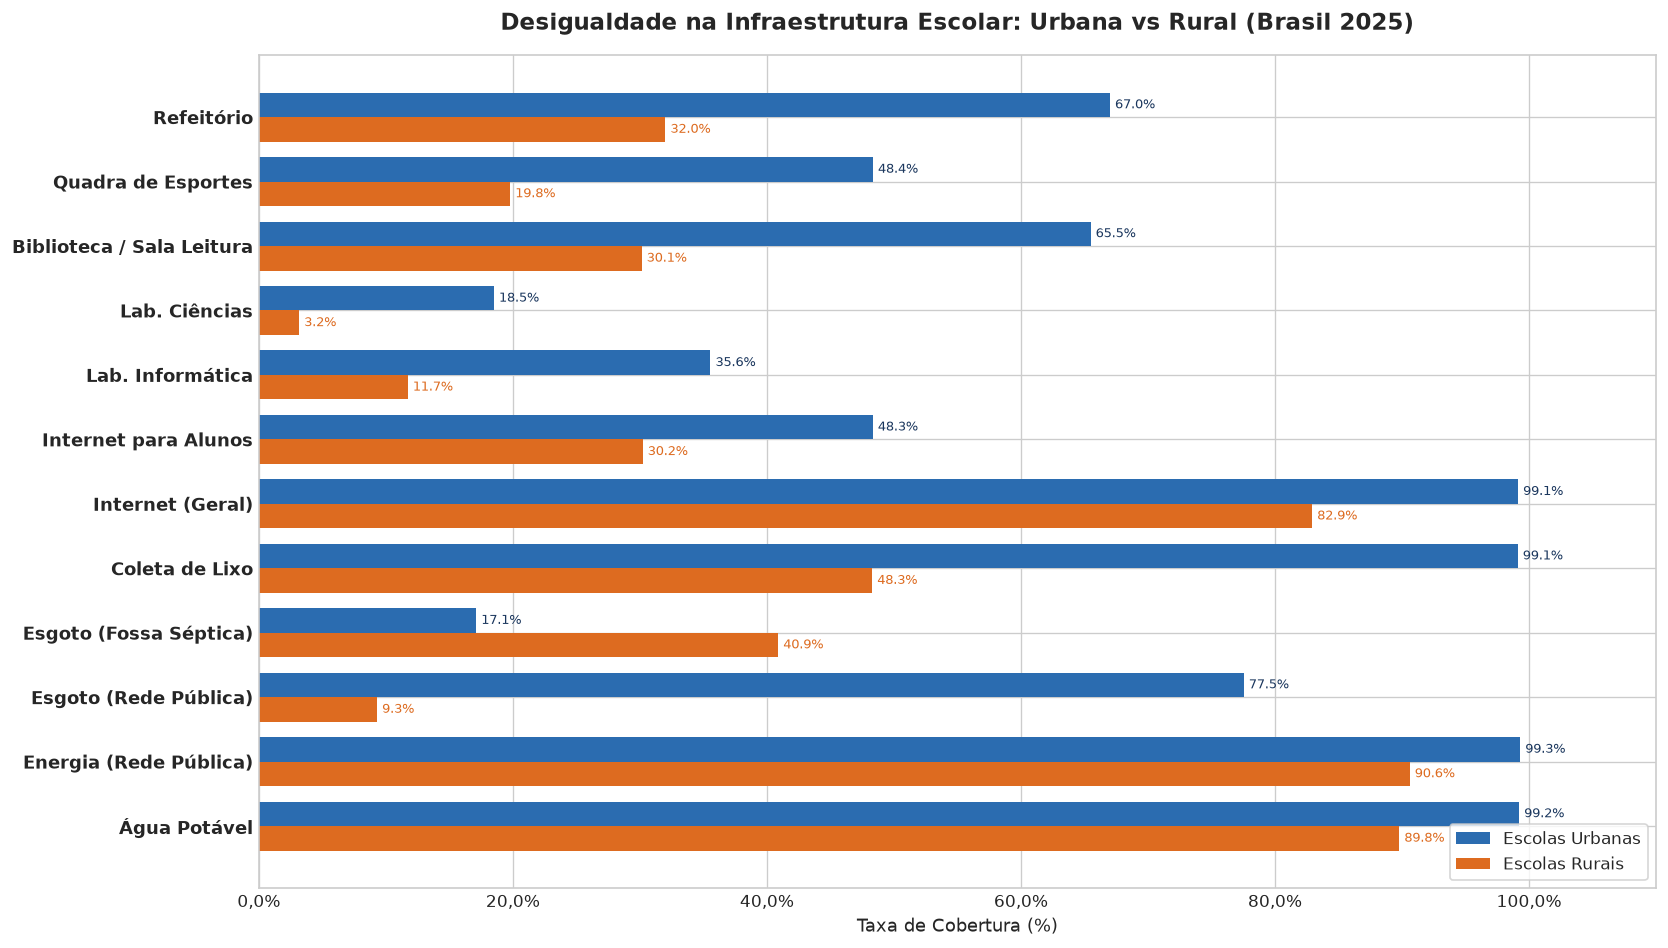

In [9]:
# Gráfico comparativo Urbano x Rural para Infraestrutura
fig, ax = plt.subplots(figsize=(14, 8))

y = np.arange(len(df_taxas_infra))
height = 0.38

bars_urb = ax.barh(y + height/2, df_taxas_infra['Urbana'], height, label='Escolas Urbanas', color=PALETA['secundaria'])
bars_rur = ax.barh(y - height/2, df_taxas_infra['Rural'], height, label='Escolas Rurais', color=PALETA['destaque'])

ax.set_yticks(y)
ax.set_yticklabels(df_taxas_infra['Indicador'], fontsize=11, fontweight='bold')
ax.set_xlabel('Taxa de Cobertura (%)', fontsize=11)
ax.set_title('Desigualdade na Infraestrutura Escolar: Urbana vs Rural (Brasil 2025)', fontsize=14, pad=15)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(fmt_pct))
ax.set_xlim(0, 110)
ax.legend(loc='lower right', frameon=True)

for bar in bars_urb:
    w = bar.get_width()
    ax.annotate(f'{w:.1f}%', xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va='center', fontsize=8, color=PALETA['primaria'])

for bar in bars_rur:
    w = bar.get_width()
    ax.annotate(f'{w:.1f}%', xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va='center', fontsize=8, color=PALETA['destaque'])

plt.tight_layout()
plt.show()


<a id='5'></a>
## 5. Radiografia das Matrículas na Educação Básica (Tabela Matrícula)

A `Tabela_Matricula_2025_V2.csv` totaliza **46.018.380 estudantes** distribuídos pelas escolas brasileiras.  
Nesta seção, exploramos o volume por etapa de ensino e o perfil sociodemográfico dos alunos.


In [10]:
cols_matricula = [
    'CO_ENTIDADE', 'QT_MAT_BAS', 'QT_MAT_INF', 'QT_MAT_INF_CRE', 'QT_MAT_INF_PRE',
    'QT_MAT_FUND', 'QT_MAT_FUND_AI', 'QT_MAT_FUND_AF', 'QT_MAT_MED',
    'QT_MAT_PROF', 'QT_MAT_EJA', 'QT_MAT_EJA_FUND', 'QT_MAT_EJA_MED', 'QT_MAT_ESP',
    # Educação Especial Geral e Estratificada
    'QT_MAT_ESP_INF', 'QT_MAT_ESP_INF_CRE', 'QT_MAT_ESP_INF_PRE',
    'QT_MAT_ESP_FUND', 'QT_MAT_ESP_FUND_AI', 'QT_MAT_ESP_FUND_AF',
    'QT_MAT_ESP_MED', 'QT_MAT_ESP_PROF', 'QT_MAT_ESP_EJA',
    'QT_MAT_ESP_EJA_FUND', 'QT_MAT_ESP_EJA_MED',
    # Classes Comuns (Inclusivas) vs Classes Exclusivas
    'QT_MAT_ESP_CC', 'QT_MAT_ESP_CC_INF_CRE', 'QT_MAT_ESP_CC_INF_PRE',
    'QT_MAT_ESP_CC_FUND_AI', 'QT_MAT_ESP_CC_FUND_AF', 'QT_MAT_ESP_CC_MED',
    'QT_MAT_ESP_CC_PROF', 'QT_MAT_ESP_CC_EJA_FUND', 'QT_MAT_ESP_CC_EJA_MED',
    'QT_MAT_ESP_CE', 'QT_MAT_ESP_CE_INF_CRE', 'QT_MAT_ESP_CE_INF_PRE',
    'QT_MAT_ESP_CE_FUND_AI', 'QT_MAT_ESP_CE_FUND_AF', 'QT_MAT_ESP_CE_MED',
    'QT_MAT_ESP_CE_PROF', 'QT_MAT_ESP_CE_EJA_FUND', 'QT_MAT_ESP_CE_EJA_MED',
    'QT_MAT_ESP_INT', 'QT_MAT_BAS_LIBRAS',
    # Tempo Integral Geral
    'QT_MAT_BAS_INT', 'QT_MAT_INF_INT', 'QT_MAT_FUND_INT', 'QT_MAT_MED_INT',
    # Demografia
    'QT_MAT_BAS_FEM', 'QT_MAT_BAS_MASC',
    'QT_MAT_BAS_BRANCA', 'QT_MAT_BAS_PRETA', 'QT_MAT_BAS_PARDA',
    'QT_MAT_BAS_AMARELA', 'QT_MAT_BAS_INDIGENA'
]

caminho_matricula = os.path.join('dados', 'Tabela_Matricula_2025_V2.csv')
df_matricula = pd.read_csv(caminho_matricula, sep=';', encoding='latin1', usecols=cols_matricula)

total_mat = df_matricula['QT_MAT_BAS'].sum()
print(f"🎓 Total Geral de Matrículas na Educação Básica em 2025: {fmt_num(total_mat)}")


🎓 Total Geral de Matrículas na Educação Básica em 2025: 46.018.380


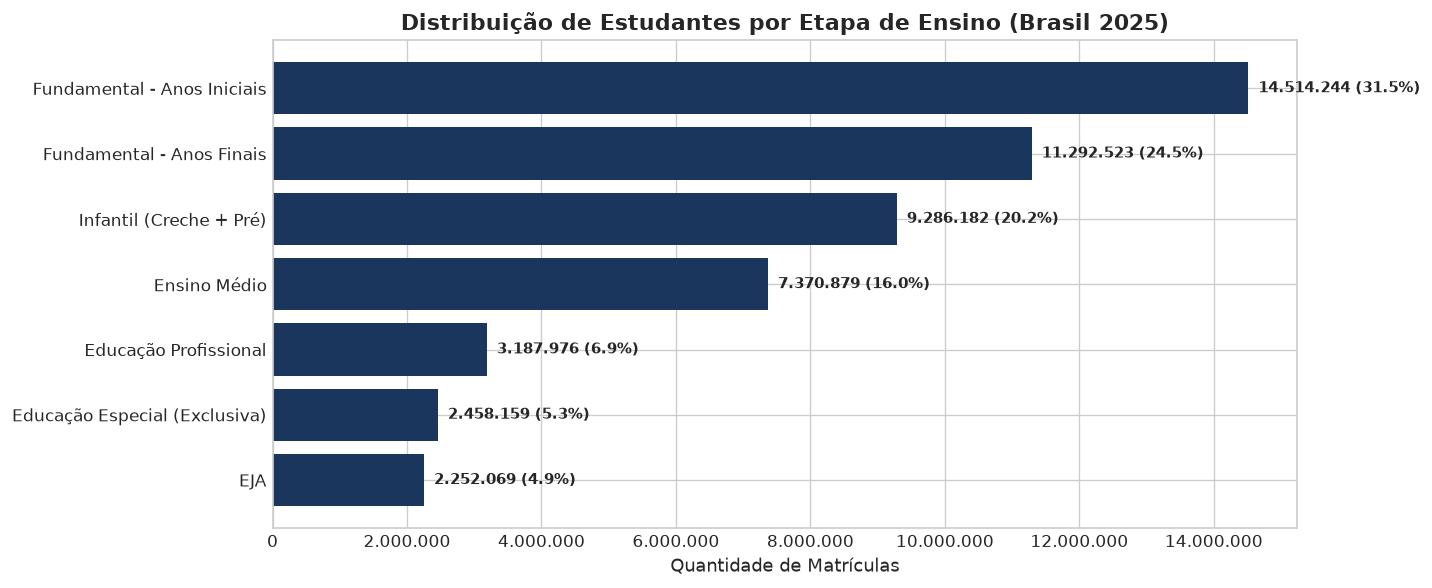

In [11]:
# Matrículas por Etapa de Ensino
etapas = {
    'Infantil (Creche + Pré)': df_matricula['QT_MAT_INF'].sum(),
    'Fundamental - Anos Iniciais': df_matricula['QT_MAT_FUND_AI'].sum(),
    'Fundamental - Anos Finais': df_matricula['QT_MAT_FUND_AF'].sum(),
    'Ensino Médio': df_matricula['QT_MAT_MED'].sum(),
    'Educação Profissional': df_matricula['QT_MAT_PROF'].sum(),
    'EJA': df_matricula['QT_MAT_EJA'].sum(),
    'Educação Especial (Exclusiva)': df_matricula['QT_MAT_ESP'].sum()
}
df_etapas = pd.DataFrame(list(etapas.items()), columns=['Etapa', 'Matrículas']).sort_values('Matrículas', ascending=False)
df_etapas['Percentual'] = (df_etapas['Matrículas'] / total_mat) * 100

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(df_etapas['Etapa'][::-1], df_etapas['Matrículas'][::-1], color=PALETA['primaria'])
ax.xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
ax.set_xlabel('Quantidade de Matrículas')
ax.set_title('Distribuição de Estudantes por Etapa de Ensino (Brasil 2025)', fontsize=13)

for bar in bars:
    w = bar.get_width()
    pct = (w / total_mat) * 100
    ax.annotate(f' {fmt_num(w)} ({pct:.1f}%)',
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


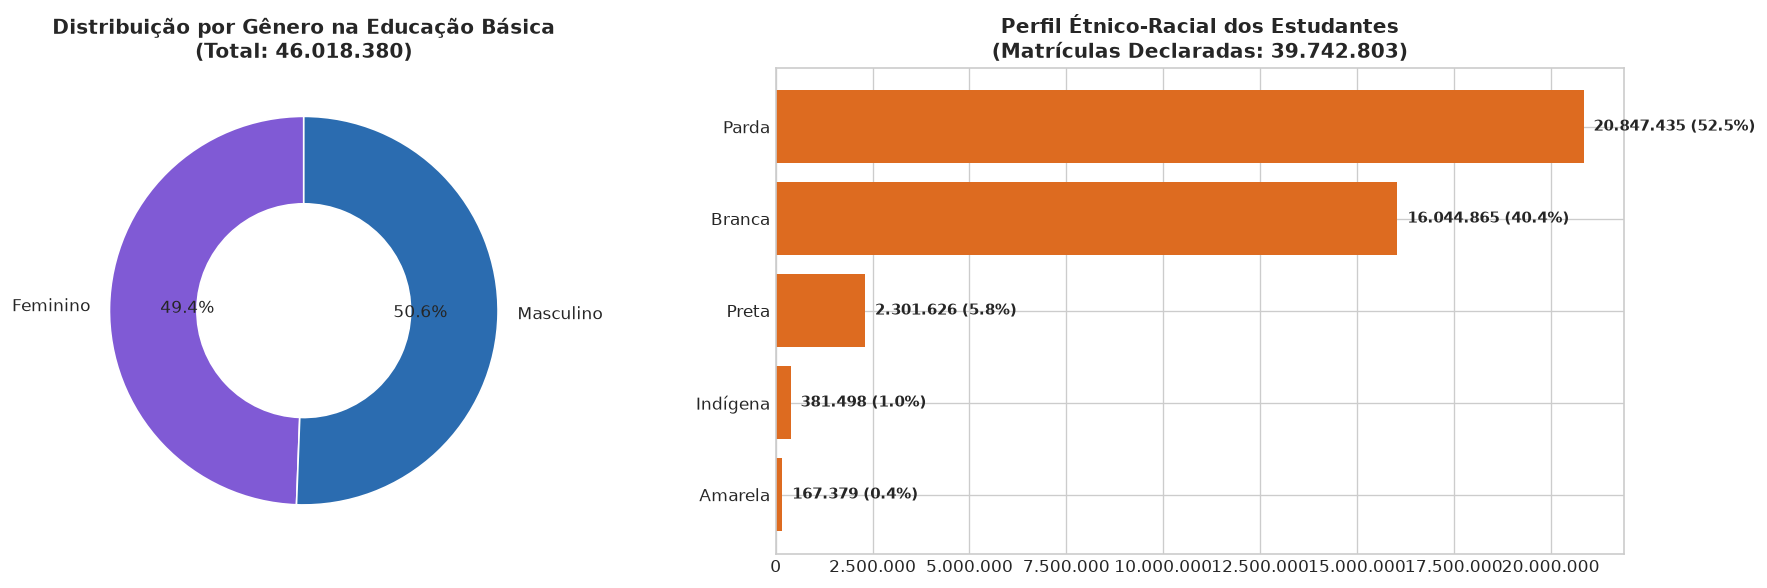

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Distribuição por Gênero
tot_fem = df_matricula['QT_MAT_BAS_FEM'].sum()
tot_masc = df_matricula['QT_MAT_BAS_MASC'].sum()
df_gen = pd.Series({'Feminino': tot_fem, 'Masculino': tot_masc})
cores_gen = [PALETA['accent'], PALETA['secundaria']]
axes[0].pie(df_gen, labels=df_gen.index, autopct='%1.1f%%', startangle=90,
            colors=cores_gen, wedgeprops=dict(width=0.45, edgecolor='w'))
axes[0].set_title(f'Distribuição por Gênero na Educação Básica\n(Total: {fmt_num(tot_fem + tot_masc)})', fontsize=12)

# 2. Distribuição por Raça/Cor
raca_cols = {
    'Parda': df_matricula['QT_MAT_BAS_PARDA'].sum(),
    'Branca': df_matricula['QT_MAT_BAS_BRANCA'].sum(),
    'Preta': df_matricula['QT_MAT_BAS_PRETA'].sum(),
    'Amarela': df_matricula['QT_MAT_BAS_AMARELA'].sum(),
    'Indígena': df_matricula['QT_MAT_BAS_INDIGENA'].sum()
}
df_raca = pd.Series(raca_cols).sort_values(ascending=True)
tot_raca_dec = df_raca.sum()
bars_r = axes[1].barh(df_raca.index, df_raca.values, color=PALETA['destaque'])
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
axes[1].set_title(f'Perfil Étnico-Racial dos Estudantes\n(Matrículas Declaradas: {fmt_num(tot_raca_dec)})', fontsize=12)
for bar in bars_r:
    w = bar.get_width()
    pct = (w / tot_raca_dec) * 100
    axes[1].annotate(f' {fmt_num(w)} ({pct:.1f}%)',
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


<a id='6'></a>
## 6. Educação Especial e Inclusão Escolar: Análise Geral e por Nível de Ensino

A **Educação Especial** abrange estudantes com deficiência (física, auditiva, visual, intelectual, surdocegueira ou múltipla), Transtorno do Espectro Autista (TEA) e altas habilidades/superdotação.

---

### 📋 Nota Metodológica e Tratamento de Dados Sensíveis (LGPD)
No questionário cadastral individual aplicado pelo Inep ([Anexos/ANEXO II - Questionários do Censo/Aluno 2025.pdf](file:///c:/Users/fabri/Downloads/microdados_censo_escolar_2025_/microdados_censo_escolar_2025_v2/Anexos/ANEXO%20II%20-%20%20Question%C3%A1rios%20do%20Censo%20da%20Educa%C3%A7%C3%A3o%20Basica/Aluno%202025.pdf), Itens 12 e 13), o Inep coleta:
- **Tipos de Deficiência**: *Cegueira, Baixa Visão, Surdez, Deficiência Auditiva, Surdocegueira, Deficiência Física, Deficiência Intelectual, Deficiência Múltipla*;
- **Transtorno do Espectro Autista (TEA)**;
- **Altas Habilidades ou Superdotação**;
- **Transtornos de Aprendizagem**: *TDAH, Discalculia, Disgrafia, Dislalia, TPAC*.

> **Privacidade e Proteção de Dados (LGPD)**: Conforme detalhado no *Relatório de Impacto à Proteção de Dados Pessoais (RIP)* do Inep, a divulgação pública do tipo médico específico de deficiência por escola representa elevado risco de reidentificação de crianças e adolescentes (dados pessoais sensíveis de saúde, Art. 5º, II da LGPD).  
> Por isso, nos microdados abertos, o Inep estrutura a informação através do contingente total da **Educação Especial (`QT_MAT_ESP`)**, estratificado por **Nível/Etapa de Ensino** e por **Tipo de Atendimento**:
> 1. **Classes Comuns (Inclusivas - `QT_MAT_ESP_CC`)**: Estudantes incluídos em turmas regulares com demais colegas;
> 2. **Classes Exclusivas (Especiais - `QT_MAT_ESP_CE`)**: Estudantes em turmas ou escolas voltadas exclusivamente à educação especial;
> 3. **Educação Bilíngue de Surdos (`QT_MAT_BAS_LIBRAS`)**.


🌟 Total de Estudantes da Educação Especial no Brasil: 2.458.159 (5.34% de todas as matrículas)
   ↳ Inclusão em Classes Comuns (Regulares): 2.298.005 (93.5%)
   ↳ Atendimento em Classes Exclusivas (Especiais): 160.154 (6.5%)
   ↳ Estudantes da Educação Especial em Tempo Integral: 865.137 (35.2%)
   ↳ Matrículas vinculadas à Educação Bilíngue de Surdos / Libras: 3.637


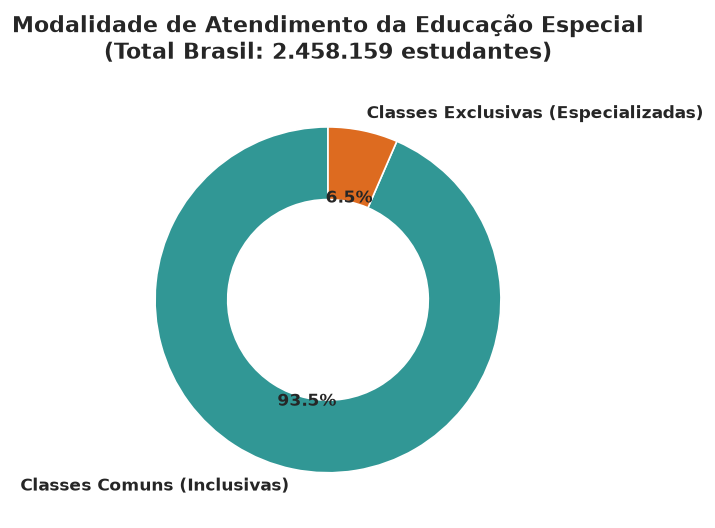

In [13]:
# 6.1 Panorama Geral da Educação Especial no Brasil (2025)
tot_esp = df_matricula['QT_MAT_ESP'].sum()
tot_esp_cc = df_matricula['QT_MAT_ESP_CC'].sum()
tot_esp_ce = df_matricula['QT_MAT_ESP_CE'].sum()
tot_libras = df_matricula['QT_MAT_BAS_LIBRAS'].sum()
tot_esp_int = df_matricula['QT_MAT_ESP_INT'].sum()

taxa_esp_geral = (tot_esp / total_mat) * 100
taxa_inclusao_cc = (tot_esp_cc / tot_esp) * 100
taxa_exclusiva_ce = (tot_esp_ce / tot_esp) * 100
taxa_esp_integral = (tot_esp_int / tot_esp) * 100

print(f"🌟 Total de Estudantes da Educação Especial no Brasil: {fmt_num(tot_esp)} ({taxa_esp_geral:.2f}% de todas as matrículas)")
print(f"   ↳ Inclusão em Classes Comuns (Regulares): {fmt_num(tot_esp_cc)} ({taxa_inclusao_cc:.1f}%)")
print(f"   ↳ Atendimento em Classes Exclusivas (Especiais): {fmt_num(tot_esp_ce)} ({taxa_exclusiva_ce:.1f}%)")
print(f"   ↳ Estudantes da Educação Especial em Tempo Integral: {fmt_num(tot_esp_int)} ({taxa_esp_integral:.1f}%)")
print(f"   ↳ Matrículas vinculadas à Educação Bilíngue de Surdos / Libras: {fmt_num(tot_libras)}")

# Gráfico de Rosca: Taxa Geral de Inclusão Escolar
fig, ax = plt.subplots(figsize=(7, 4.5))
df_mod_esp = pd.Series({'Classes Comuns (Inclusivas)': tot_esp_cc, 'Classes Exclusivas (Especializadas)': tot_esp_ce})
cores_mod = [PALETA['inclusao'], PALETA['destaque']]

wedges, texts, autotexts = ax.pie(
    df_mod_esp, labels=df_mod_esp.index, autopct='%1.1f%%', startangle=90,
    colors=cores_mod, wedgeprops=dict(width=0.42, edgecolor='w'),
    textprops=dict(fontsize=10, fontweight='bold')
)
ax.set_title(f'Modalidade de Atendimento da Educação Especial\n(Total Brasil: {fmt_num(tot_esp)} estudantes)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()


In [14]:
# 6.2 Estratificação da Educação Especial por Nível e Etapa de Ensino
niveis_esp = {
    'Infantil - Creche': ('QT_MAT_ESP_INF_CRE', 'QT_MAT_ESP_CC_INF_CRE', 'QT_MAT_ESP_CE_INF_CRE', 'QT_MAT_INF_CRE'),
    'Infantil - Pré-Escola': ('QT_MAT_ESP_INF_PRE', 'QT_MAT_ESP_CC_INF_PRE', 'QT_MAT_ESP_CE_INF_PRE', 'QT_MAT_INF_PRE'),
    'Fundamental - Anos Iniciais': ('QT_MAT_ESP_FUND_AI', 'QT_MAT_ESP_CC_FUND_AI', 'QT_MAT_ESP_CE_FUND_AI', 'QT_MAT_FUND_AI'),
    'Fundamental - Anos Finais': ('QT_MAT_ESP_FUND_AF', 'QT_MAT_ESP_CC_FUND_AF', 'QT_MAT_ESP_CE_FUND_AF', 'QT_MAT_FUND_AF'),
    'Ensino Médio': ('QT_MAT_ESP_MED', 'QT_MAT_ESP_CC_MED', 'QT_MAT_ESP_CE_MED', 'QT_MAT_MED'),
    'Educação Profissional': ('QT_MAT_ESP_PROF', 'QT_MAT_ESP_CC_PROF', 'QT_MAT_ESP_CE_PROF', 'QT_MAT_PROF'),
    'EJA - Fundamental': ('QT_MAT_ESP_EJA_FUND', 'QT_MAT_ESP_CC_EJA_FUND', 'QT_MAT_ESP_CE_EJA_FUND', 'QT_MAT_EJA_FUND'),
    'EJA - Médio': ('QT_MAT_ESP_EJA_MED', 'QT_MAT_ESP_CC_EJA_MED', 'QT_MAT_ESP_CE_EJA_MED', 'QT_MAT_EJA_MED')
}

linhas_esp = []
for nome, (col_tot, col_cc, col_ce, col_geral) in niveis_esp.items():
    v_esp = df_matricula[col_tot].sum()
    v_cc = df_matricula[col_cc].sum()
    v_ce = df_matricula[col_ce].sum()
    v_geral = df_matricula[col_geral].sum()
    
    prop_esp = (v_esp / v_geral) * 100 if v_geral > 0 else 0
    taxa_inc = (v_cc / v_esp) * 100 if v_esp > 0 else 0
    taxa_exc = (v_ce / v_esp) * 100 if v_esp > 0 else 0
    
    linhas_esp.append({
        'Nível / Etapa de Ensino': nome,
        'Matrículas Totais': v_geral,
        'Educação Especial': v_esp,
        'Participação Especial (%)': prop_esp,
        'Classes Comuns (Inclusivas)': v_cc,
        'Classes Exclusivas': v_ce,
        'Taxa de Inclusão (%)': taxa_inc
    })

df_tabela_esp = pd.DataFrame(linhas_esp)

print("📊 Tabela Estratificada: Educação Especial por Nível e Etapa de Ensino (Brasil 2025)")
display(df_tabela_esp.style.format({
    'Matrículas Totais': lambda x: fmt_num(x),
    'Educação Especial': lambda x: fmt_num(x),
    'Participação Especial (%)': '{:.2f}%',
    'Classes Comuns (Inclusivas)': lambda x: fmt_num(x),
    'Classes Exclusivas': lambda x: fmt_num(x),
    'Taxa de Inclusão (%)': '{:.1f}%'
}).bar(subset=['Participação Especial (%)'], color=PALETA['neutro_cla'])
  .bar(subset=['Taxa de Inclusão (%)'], color='#B2F5EA', vmin=50, vmax=100))


📊 Tabela Estratificada: Educação Especial por Nível e Etapa de Ensino (Brasil 2025)


AttributeError: The '.style' accessor requires jinja2

In [ ]:
# 6.3 Visualizações Gráficas: Volume e Taxa de Inclusão por Nível de Ensino
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Volume Absoluto de Estudantes da Educação Especial por Nível
y_pos = np.arange(len(df_tabela_esp))
etapas_nomes = df_tabela_esp['Nível / Etapa de Ensino'][::-1]
vals_esp = df_tabela_esp['Educação Especial'][::-1]

bars_v = axes[0].barh(y_pos, vals_esp, color=PALETA['inclusao'])
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(etapas_nomes, fontsize=10, fontweight='bold')
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
axes[0].set_title('Estudantes da Educação Especial por Nível de Ensino', fontsize=12)
axes[0].set_xlabel('Quantidade de Matrículas')

for bar in bars_v:
    w = bar.get_width()
    pct_pais = (w / tot_esp) * 100
    axes[0].annotate(f' {fmt_num(w)} ({pct_pais:.1f}%)',
                     xy=(w, bar.get_y() + bar.get_height() / 2),
                     xytext=(3, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

# 2. Taxa de Inclusão (Classes Comuns vs Classes Exclusivas) por Nível (Barras 100% Empilhadas)
taxas_cc = df_tabela_esp['Classes Comuns (Inclusivas)'][::-1] / vals_esp * 100
taxas_ce = df_tabela_esp['Classes Exclusivas'][::-1] / vals_esp * 100

axes[1].barh(y_pos, taxas_cc, label='Classes Comuns (Inclusivas)', color=PALETA['secundaria'], height=0.55)
axes[1].barh(y_pos, taxas_ce, left=taxas_cc, label='Classes Exclusivas (Especiais)', color=PALETA['destaque'], height=0.55)

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(etapas_nomes, fontsize=10, fontweight='bold')
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(fmt_pct))
axes[1].set_xlim(0, 105)
axes[1].set_title('Proporção de Inclusão em Classes Comuns por Nível (%)', fontsize=12)
axes[1].set_xlabel('Proporção (%)')
axes[1].legend(loc='lower left', frameon=True)

for i, (t_cc, t_ce) in enumerate(zip(taxas_cc, taxas_ce)):
    axes[1].annotate(f'{t_cc:.1f}%', xy=(t_cc/2, i), ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    if t_ce > 6:
        axes[1].annotate(f'{t_ce:.1f}%', xy=(t_cc + t_ce/2, i), ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:
# 6.4 Recursos de Acessibilidade e Apoio Pedagógico nas Escolas Ativas
# Avaliamos os recursos físicos e profissionais destinados ao atendimento das deficiências
recursos_acess = {
    'Sala de Recursos Multifuncionais (AEE)': (df_escola['IN_SALA_ATENDIMENTO_ESPECIAL'] == 1).mean() * 100,
    'Profissionais Tradutores de Libras': (df_escola['QT_PROF_TRAD_LIBRAS'] > 0).mean() * 100,
    'Profissionais Revisores de Braille': (df_escola['QT_PROF_REVISOR_BRAILLE'] > 0).mean() * 100,
    'Rampas de Acesso': (df_escola['IN_ACESSIBILIDADE_RAMPAS'] == 1).mean() * 100,
    'Corrimãos / Guarda-corpos': (df_escola['IN_ACESSIBILIDADE_CORRIMAO'] == 1).mean() * 100,
    'Elevadores Adaptados': (df_escola['IN_ACESSIBILIDADE_ELEVADOR'] == 1).mean() * 100,
    'Piso Tátil': (df_escola['IN_ACESSIBILIDADE_PISOS_TATEIS'] == 1).mean() * 100,
    'Inexistência Total de Acessibilidade': (df_escola['IN_ACESSIBILIDADE_INEXISTENTE'] == 1).mean() * 100
}

df_recursos = pd.Series(recursos_acess).sort_values(ascending=True)

plt.figure(figsize=(12, 5))
cores_acess = [PALETA['alerta'] if 'Inexistência' in k else PALETA['inclusao'] for k in df_recursos.index]
bars_ac = plt.barh(df_recursos.index, df_recursos.values, color=cores_acess)
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(fmt_pct))
plt.xlim(0, 70)
plt.title('Taxa de Escolas Ativas com Recursos de Acessibilidade e Apoio à Educação Especial (%)', fontsize=12, pad=12)
plt.xlabel('Percentual de Escolas Ativas (%)')

for bar in bars_ac:
    w = bar.get_width()
    plt.annotate(f' {w:.1f}%',
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(3, 0), textcoords="offset points",
                 va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


<a id='7'></a>
## 7. A Política de Expansão do Tempo Integral

A expansão de matrículas em **Tempo Integral** (jornada igual ou superior a 7 horas diárias) é uma meta prioritária do Plano Nacional de Educação (PNE).  
Examinamos a cobertura global e a distribuição entre as etapas da educação básica.


In [ ]:
# Análise da Educação em Tempo Integral
tot_int = df_matricula['QT_MAT_BAS_INT'].sum()
taxa_int_global = (tot_int / total_mat) * 100

int_etapas = {
    'Infantil': (df_matricula['QT_MAT_INF_INT'].sum(), df_matricula['QT_MAT_INF'].sum()),
    'Fundamental': (df_matricula['QT_MAT_FUND_INT'].sum(), df_matricula['QT_MAT_FUND'].sum()),
    'Ensino Médio': (df_matricula['QT_MAT_MED_INT'].sum(), df_matricula['QT_MAT_MED'].sum())
}

df_int_etapas = pd.DataFrame([
    {
        'Etapa': etapa,
        'Matrículas Integral': vals[0],
        'Matrículas Totais': vals[1],
        'Taxa de Cobertura (%)': (vals[0] / vals[1]) * 100
    }
    for etapa, vals in int_etapas.items()
])

print(f"⏰ Total de estudantes em Tempo Integral: {fmt_num(tot_int)} ({taxa_int_global:.1f}% do total)")
display(df_int_etapas.style.format({
    'Matrículas Integral': lambda x: fmt_num(x),
    'Matrículas Totais': lambda x: fmt_num(x),
    'Taxa de Cobertura (%)': '{:.1f}%'
}))


<a id='8'></a>
## 8. Corpo Docente e Dinâmica de Turmas (Tabelas Docente e Turma)

A qualidade da aprendizagem está intimamente conectada à formação e condições de trabalho dos professores e à densidade de alunos por sala.  
Carregamos as tabelas `Tabela_Docente_2025_V2.csv` e `Tabela_Turma_2025_V2.csv`.


In [ ]:
cols_docente = [
    'CO_ENTIDADE', 'QT_DOC_BAS', 'QT_DOC_BAS_FEM', 'QT_DOC_BAS_MASC',
    'QT_DOC_BAS_ESCO_SUP_GRAD', 'QT_DOC_BAS_ESCO_SUP_GRAD_LICEN',
    'QT_DOC_BAS_ESCO_SUP_POS_ESPEC', 'QT_DOC_BAS_ESCO_SUP_POS_MESTRA',
    'QT_DOC_BAS_ESCO_SUP_POS_DOUTO'
]

caminho_docente = os.path.join('dados', 'Tabela_Docente_2025_V2.csv')
df_docente = pd.read_csv(caminho_docente, sep=';', encoding='latin1', usecols=cols_docente)

tot_doc_bas = df_docente['QT_DOC_BAS'].sum()
tot_doc_sup = df_docente['QT_DOC_BAS_ESCO_SUP_GRAD'].sum()
tot_doc_pos = df_docente['QT_DOC_BAS_ESCO_SUP_POS_ESPEC'].sum() + df_docente['QT_DOC_BAS_ESCO_SUP_POS_MESTRA'].sum() + df_docente['QT_DOC_BAS_ESCO_SUP_POS_DOUTO'].sum()

print(f"👩‍🏫 Total de Funções Docentes na Educação Básica: {fmt_num(tot_doc_bas)}")
print(f"   ↳ Com Nível Superior / Graduação: {fmt_num(tot_doc_sup)} ({(tot_doc_sup / tot_doc_bas) * 100:.1f}%)")
print(f"   ↳ Com Pós-Graduação (Especialização/Mestrado/Doutorado): {fmt_num(tot_doc_pos)} ({(tot_doc_pos / tot_doc_bas) * 100:.1f}%)")

# Relação de Alunos por Turma
cols_turma = ['CO_ENTIDADE', 'QT_TUR_BAS', 'QT_TUR_INF', 'QT_TUR_FUND', 'QT_TUR_MED']
caminho_turma = os.path.join('dados', 'Tabela_Turma_2025_V2.csv')
df_turma = pd.read_csv(caminho_turma, sep=';', encoding='latin1', usecols=cols_turma)

tot_turmas_bas = df_turma['QT_TUR_BAS'].sum()
media_aluno_turma = total_mat / tot_turmas_bas
print(f"🏫 Total de Turmas Registradas: {fmt_num(tot_turmas_bas)}")
print(f"👥 Média Nacional de Alunos por Turma: {media_aluno_turma:.1f} alunos/turma")


<a id='9'></a>
## 9. Liderança e Gestão Escolar (Tabela Gestor)

A `Tabela_Gestor_Escolar_2025_v2.csv` permite compreender o perfil sociodemográfico e os mecanismos de acesso ao cargo de diretor escolar, critério fundamental estabelecido pelo Plano Nacional de Educação (PNE).


In [ ]:
cols_gestor = [
    'CO_ENTIDADE', 'QT_GEST_BAS', 'QT_GEST_BAS_FEM', 'QT_GEST_BAS_MASC',
    'QT_GEST_BAS_BRANCA', 'QT_GEST_BAS_PRETA', 'QT_GEST_BAS_PARDA',
    'QT_GEST_BAS_ACESSO_CARGO_CONC', 'QT_GEST_BAS_ACESSO_CARGO_ELEIC',
    'QT_GEST_BAS_ACESSO_CARGO_INDIC', 'QT_GEST_BAS_ACESSO_CARGO_SEL',
    'QT_GEST_BAS_ACESSO_CARGO_P_SEL'
]

caminho_gestor = os.path.join('dados', 'Tabela_Gestor_Escolar_2025_v2.csv')
df_gestor = pd.read_csv(caminho_gestor, sep=';', encoding='latin1', usecols=cols_gestor)

# Formas de provimento ao cargo de diretor
provimentos = {
    'Indicação': df_gestor['QT_GEST_BAS_ACESSO_CARGO_INDIC'].sum(),
    'Eleição com a Comunidade': df_gestor['QT_GEST_BAS_ACESSO_CARGO_ELEIC'].sum(),
    'Processo Seletivo Técnico': df_gestor['QT_GEST_BAS_ACESSO_CARGO_SEL'].sum(),
    'Concurso Público': df_gestor['QT_GEST_BAS_ACESSO_CARGO_CONC'].sum(),
    'Misto (Processo Seletivo + Eleição)': df_gestor['QT_GEST_BAS_ACESSO_CARGO_P_SEL'].sum()
}
df_prov = pd.Series(provimentos).sort_values(ascending=False)
tot_prov = df_prov.sum()

plt.figure(figsize=(10, 4.5))
bars_p = plt.barh(df_prov.index[::-1], df_prov.values[::-1], color=PALETA['sucesso'])
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
plt.title(f'Forma de Acesso / Provimento ao Cargo de Gestor Escolar\n(Total Declarado: {fmt_num(tot_prov)})', fontsize=12)
plt.xlabel('Quantidade de Gestores')

for bar in bars_p:
    w = bar.get_width()
    pct = (w / tot_prov) * 100
    plt.annotate(f' {fmt_num(w)} ({pct:.1f}%)',
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(3, 0), textcoords="offset points",
                 va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


<a id='10'></a>
## 10. Educação Profissional e Cursos Técnicos (Tabela Curso Técnico)

A `Tabela_Curso_Tecnico_2025_V2.csv` detalha a oferta de cursos de educação profissional técnica de nível médio.  
Investigamos quais são os cursos técnicos com maior número de matrículas no país.


In [ ]:
caminho_ct = os.path.join('dados', 'Tabela_Curso_Tecnico_2025_V2.csv')
df_ct = pd.read_csv(caminho_ct, sep=';', encoding='latin1', usecols=['NO_CURSO_EDUC_PROFISSIONAL', 'QT_MAT_CURSO_TEC', 'SG_UF'])

top_cursos = df_ct.groupby('NO_CURSO_EDUC_PROFISSIONAL')['QT_MAT_CURSO_TEC'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
bars_c = plt.barh(top_cursos.index[::-1], top_cursos.values[::-1], color=PALETA['secundaria'])
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(fmt_num))
plt.title('Top 10 Cursos Técnicos com Maior Volume de Matrículas no Brasil (2025)', fontsize=13)
plt.xlabel('Número de Estudantes Matriculados')

for bar in bars_c:
    w = bar.get_width()
    plt.annotate(f' {fmt_num(w)}',
                 xy=(w, bar.get_y() + bar.get_height() / 2),
                 xytext=(3, 0), textcoords="offset points",
                 va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


<a id='11'></a>
## 11. Análise Integrada (Join Escola + Matrículas)

Conforme recomendado no Manual do Usuário (`Leia-me_v2.pdf`), integramos as tabelas através da chave primária `CO_ENTIDADE`.  
Construímos um **Índice Sintético de Infraestrutura Básica Completa** (Água Potável + Energia + Esgoto Adequado + Internet + Biblioteca/Leitura) e cruzamos com o porte da escola (número de matrículas) e a rede de ensino.


In [ ]:
# Junção entre Escola e Matrícula
df_consolidado = pd.merge(
    df_escola,
    df_matricula[['CO_ENTIDADE', 'QT_MAT_BAS', 'QT_MAT_BAS_INT', 'QT_MAT_ESP']],
    on='CO_ENTIDADE',
    how='inner'
)

# Criação do Indicador Sintético de Infraestrutura Básica Completa (0 a 5)
df_consolidado['IND_INFRA_COMPLETA'] = (
    (df_consolidado['IN_AGUA_POTAVEL'] == 1).astype(int) +
    (df_consolidado['IN_ENERGIA_REDE_PUBLICA'] == 1).astype(int) +
    ((df_consolidado['IN_ESGOTO_REDE_PUBLICA'] == 1) | (df_consolidado['IN_ESGOTO_FOSSA_SEPTICA'] == 1)).astype(int) +
    (df_consolidado['IN_INTERNET'] == 1).astype(int) +
    (df_consolidado['IN_BIBLIOTECA_SALA_LEITURA'] == 1).astype(int)
)

# Porte da Escola baseado nas matrículas da Educação Básica
def classificar_porte(qtd):
    if qtd <= 50:
        return '1. Pequeno Porte (até 50)'
    elif qtd <= 200:
        return '2. Médio-Baixo (51 a 200)'
    elif qtd <= 500:
        return '3. Médio (201 a 500)'
    elif qtd <= 1000:
        return '4. Grande (501 a 1000)'
    else:
        return '5. Mega Escola (> 1000)'

df_consolidado['PORTE_ESCOLA'] = df_consolidado['QT_MAT_BAS'].apply(classificar_porte)

# Tabela cruzada: Porte da Escola vs Média do Índice de Infraestrutura
porte_resumo = df_consolidado.groupby('PORTE_ESCOLA').agg(
    Qtd_Escolas=('CO_ENTIDADE', 'count'),
    Total_Matriculas=('QT_MAT_BAS', 'sum'),
    Total_Educ_Especial=('QT_MAT_ESP', 'sum'),
    Media_Infra=('IND_INFRA_COMPLETA', 'mean')
)
display(porte_resumo.style.format({
    'Qtd_Escolas': lambda x: fmt_num(x),
    'Total_Matriculas': lambda x: fmt_num(x),
    'Total_Educ_Especial': lambda x: fmt_num(x),
    'Media_Infra': '{:.2f} / 5,00'
}))


In [ ]:
# Ranking dos 10 Municípios com Maior Volume de Matrículas em 2025
top_municipios = df_consolidado.groupby(['NO_MUNICIPIO', 'SG_UF']).agg(
    Matriculas=('QT_MAT_BAS', 'sum'),
    Escolas=('CO_ENTIDADE', 'count'),
    Educ_Especial=('QT_MAT_ESP', 'sum'),
    Taxa_Internet=('IN_INTERNET', lambda x: (x == 1).mean() * 100),
    Media_Infra=('IND_INFRA_COMPLETA', 'mean')
).sort_values('Matriculas', ascending=False).head(10)

print("🏆 Top 10 Municípios em Volume de Estudantes na Educação Básica:")
display(top_municipios.style.format({
    'Matriculas': lambda x: fmt_num(x),
    'Escolas': lambda x: fmt_num(x),
    'Educ_Especial': lambda x: fmt_num(x),
    'Taxa_Internet': '{:.1f}%',
    'Media_Infra': '{:.2f} / 5,0'
}))
